<a href="https://colab.research.google.com/github/MuhammadAmaan178/Demand-Lens/blob/main/notebooks/Dlens_07_lightgbm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Load 7-Day Horizon Train & Validation Datasets

In [1]:
import pandas as pd

train_7 = pd.read_parquet('/content/ca1_h7_train.parquet')
val_7 = pd.read_parquet('/content/ca1_h7_val.parquet')

print(f"train_7 shape: {train_7.shape}")
print(f"val_7 shape: {val_7.shape}")

train_7 shape: (4552041, 26)
val_7 shape: (85372, 26)


### Load 28-Day Horizon Train & Validation Datasets

In [2]:
train_28 = pd.read_parquet('/content/ca1_h28_train.parquet')
val_28 = pd.read_parquet('/content/ca1_h28_val.parquet')

print(f"train_28 shape: {train_28.shape}")
print(f"val_28 shape: {val_28.shape}")

train_28 shape: (4424067, 26)
val_28 shape: (85359, 26)


In [3]:
pd.set_option("display.max_columns", None)

In [4]:
train_7.head()

,item_id,store_id,date,sales,lag_7,rolling_mean_7,wday,month,year,is_weekend,snap,has_event,sell_price,price_change,ev_Cultural,ev_National,ev_Religious,ev_Sporting,ev_None,dept_FOODS_1,dept_FOODS_2,dept_FOODS_3,dept_HOBBIES_1,dept_HOBBIES_2,dept_HOUSEHOLD_1,dept_HOUSEHOLD_2
0,FOODS_1_001,CA_1,2011-02-09,0,4.0,1.600000,5,2,2011,0,1,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
1,FOODS_1_001,CA_1,2011-02-10,3,2.0,1.666667,6,2,2011,0,1,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
2,FOODS_1_001,CA_1,2011-02-11,1,0.0,1.428571,7,2,2011,0,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
3,FOODS_1_001,CA_1,2011-02-12,3,2.0,1.285714,1,2,2011,1,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
4,FOODS_1_001,CA_1,2011-02-13,0,0.0,1.285714,2,2,2011,1,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0


In [5]:
train_28.head()

,item_id,store_id,date,sales,lag_28,rolling_mean_28,wday,month,year,is_weekend,snap,has_event,sell_price,price_change,ev_Cultural,ev_National,ev_Religious,ev_Sporting,ev_None,dept_FOODS_1,dept_FOODS_2,dept_FOODS_3,dept_HOBBIES_1,dept_HOBBIES_2,dept_HOUSEHOLD_1,dept_HOUSEHOLD_2
0,FOODS_1_001,CA_1,2011-03-23,1,2.0,1.269231,5,3,2011,0,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
1,FOODS_1_001,CA_1,2011-03-24,0,2.0,1.296296,6,3,2011,0,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
2,FOODS_1_001,CA_1,2011-03-25,1,4.0,1.392857,7,3,2011,0,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
3,FOODS_1_001,CA_1,2011-03-26,2,2.0,1.357143,1,3,2011,1,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0
4,FOODS_1_001,CA_1,2011-03-27,2,2.0,1.428571,2,3,2011,1,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0


In [6]:
drop_cols = ["item_id", "store_id", "date", "sales"]

In [7]:
# 7-Day Horizon
X_train_7 = train_7.drop(columns=drop_cols)
y_train_7 = train_7["sales"]
X_val_7   = val_7.drop(columns=drop_cols)
y_val_7   = val_7["sales"]

In [8]:
# 28-Day Horizon
X_train_28 = train_28.drop(columns=drop_cols)
y_train_28 = train_28["sales"]
X_val_28   = val_28.drop(columns=drop_cols)
y_val_28   = val_28["sales"]

In [9]:
X_train_7.shape, y_train_7.shape, X_val_7.shape, y_val_7.shape

((4552041, 22), (4552041,), (85372, 22), (85372,))

In [10]:
import lightgbm as lgb
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

In [11]:
def evaluate_forecast(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.clip(np.asarray(y_pred), 0, None)

    wape = (np.sum(np.abs(y_true - y_pred)) / max(np.sum(np.abs(y_true)), 1e-10)) * 100
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    return {
        "WAPE (%)": round(float(wape), 2),
        "MAE": round(float(mae), 4),
        "RMSE": round(float(rmse), 4)
    }

In [12]:
def train_lightgbm(X_train, y_train, X_val, y_val):
    model = lgb.LGBMRegressor(
        objective="regression",
        n_estimators=3000,
        learning_rate=0.03,
        num_leaves=40,
        max_depth=-1,
        min_child_samples=30,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_alpha=0.5,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        callbacks=[
            lgb.early_stopping(100),
            lgb.log_evaluation(100)
        ]
    )

    return model

In [13]:
model_7 = train_lightgbm(X_train_7, y_train_7, X_val_7, y_val_7)
print("7-Day LightGBM V1 Training Completed!")

model_28 = train_lightgbm(X_train_28, y_train_28, X_val_28, y_val_28)
print("28-Day LightGBM V1 Training Completed!")

Training until validation scores don't improve for 100 rounds
[100]	valid_0's l2: 4.70898
[200]	valid_0's l2: 4.66613
[300]	valid_0's l2: 4.6641
[400]	valid_0's l2: 4.66398
Early stopping, best iteration is:
[367]	valid_0's l2: 4.65882
7-Day LightGBM V1 Training Completed!
Training until validation scores don't improve for 100 rounds
[100]	valid_0's l2: 4.93129
[200]	valid_0's l2: 4.82153
[300]	valid_0's l2: 4.79718
[400]	valid_0's l2: 4.78997
[500]	valid_0's l2: 4.79306
Early stopping, best iteration is:
[410]	valid_0's l2: 4.78882
28-Day LightGBM V1 Training Completed!


In [14]:
# 7-Day Predictions
y_pred_7 = model_7.predict(X_val_7)

# 28-Day Predictions
y_pred_28 = model_28.predict(X_val_28)

In [15]:
# Evaluate 7-Day Model
results_7 = evaluate_forecast(
    y_val_7,
    y_pred_7
)

# Evaluate 28-Day Model
results_28 = evaluate_forecast(
    y_val_28,
    y_pred_28
)

In [16]:
# Sanity check store count, item count, and date splits
print("Unique items :", train_7["item_id"].nunique())
print("Unique stores:", train_7["store_id"].nunique())
print("Train dates  :", train_7["date"].min(), "to", train_7["date"].max())
print("Val dates    :", val_7["date"].min(), "to", val_7["date"].max())

Unique items : 3049
Unique stores: 1
Train dates  : 2011-02-09 00:00:00 to 2016-03-27 00:00:00
Val dates    : 2016-03-28 00:00:00 to 2016-04-24 00:00:00


In [17]:
# Check sales distribution and percentage of zero-sales days
zero_pct = (train_7["sales"] == 0).mean() * 100
print(f"\nZero-sales rows in train: {zero_pct:.2f}%")
print(train_7["sales"].describe().round(3))


Zero-sales rows in train: 55.18%
count    4552041.000
mean           1.645
std            4.479
min            0.000
25%            0.000
50%            0.000
75%            2.000
max          648.000
Name: sales, dtype: float64


In [18]:
# Check average daily sales by weekday (justifying cyclical wday_sin/wday_cos features)
wday_sales = train_7.groupby("wday")["sales"].mean().round(3)
print("Average sales by day of week (wday 1 to 7):")
print(wday_sales)

Average sales by day of week (wday 1 to 7):
wday
1    2.062
2    2.095
3    1.571
4    1.395
5    1.361
6    1.376
7    1.649
Name: sales, dtype: float64


In [26]:
def prepare_features(train_df, val_df):
    train_df = train_df.copy()
    val_df = val_df.copy()

    # Item ID as categorical with identical category order
    categories = train_df["item_id"].astype(str).unique()
    train_df["item_id"] = pd.Categorical(train_df["item_id"].astype(str), categories=categories)
    val_df["item_id"] = pd.Categorical(val_df["item_id"].astype(str), categories=categories)

    # Cyclical weekday features
    train_df["wday_sin"] = np.sin(2 * np.pi * (train_df["wday"] - 1) / 7)
    train_df["wday_cos"] = np.cos(2 * np.pi * (train_df["wday"] - 1) / 7)
    val_df["wday_sin"] = np.sin(2 * np.pi * (val_df["wday"] - 1) / 7)
    val_df["wday_cos"] = np.cos(2 * np.pi * (val_df["wday"] - 1) / 7)

    # Cyclical month features
    train_df["month_sin"] = np.sin(2 * np.pi * (train_df["month"] - 1) / 12)
    train_df["month_cos"] = np.cos(2 * np.pi * (train_df["month"] - 1) / 12)
    val_df["month_sin"] = np.sin(2 * np.pi * (val_df["month"] - 1) / 12)
    val_df["month_cos"] = np.cos(2 * np.pi * (val_df["month"] - 1) / 12)

    return train_df, val_df

In [27]:
train_7, val_7 = prepare_features(train_7, val_7)
train_28, val_28 = prepare_features(train_28, val_28)

In [33]:
drop_cols_v2 = ["store_id", "date", "sales"]

X_train_7 = train_7.drop(columns=drop_cols_v2)
y_train_7 = train_7["sales"]
X_val_7 = val_7.drop(columns=drop_cols_v2)
y_val_7 = val_7["sales"]

X_train_28 = train_28.drop(columns=drop_cols_v2)
y_train_28 = train_28["sales"]
X_val_28 = val_28.drop(columns=drop_cols_v2)
y_val_28 = val_28["sales"]

assert list(X_train_7.columns) == list(X_val_7.columns)
assert list(X_train_28.columns) == list(X_val_28.columns)

print("7-Day  V2:", X_train_7.shape, X_val_7.shape)
print("28-Day V2:", X_train_28.shape, X_val_28.shape)

7-Day  V2: (4552041, 27) (85372, 27)
28-Day V2: (4424067, 27) (85359, 27)


In [34]:
X_train_7.head()

,item_id,lag_7,rolling_mean_7,wday,month,year,is_weekend,snap,has_event,sell_price,price_change,ev_Cultural,ev_National,ev_Religious,ev_Sporting,ev_None,dept_FOODS_1,dept_FOODS_2,dept_FOODS_3,dept_HOBBIES_1,dept_HOBBIES_2,dept_HOUSEHOLD_1,dept_HOUSEHOLD_2,wday_sin,wday_cos,month_sin,month_cos
0,FOODS_1_001,4.0,1.600000,5,2,2011,0,1,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0,-0.433884,-0.900969,0.5,0.866025
1,FOODS_1_001,2.0,1.666667,6,2,2011,0,1,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0,-0.974928,-0.222521,0.5,0.866025
2,FOODS_1_001,0.0,1.428571,7,2,2011,0,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0,-0.781831,0.623490,0.5,0.866025
3,FOODS_1_001,2.0,1.285714,1,2,2011,1,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0,0.000000,1.000000,0.5,0.866025
4,FOODS_1_001,0.0,1.285714,2,2,2011,1,0,0,2.0,0.0,0,0,0,0,1,1,0,0,0,0,0,0,0.781831,0.623490,0.5,0.866025


In [35]:
def train_lightgbm_v2(X_train, y_train, X_val, y_val, power=1.1):
    model = lgb.LGBMRegressor(
        objective="tweedie",
        tweedie_variance_power=power,
        metric="rmse",
        n_estimators=1000,
        learning_rate=0.05,
        num_leaves=63,
        min_child_samples=50,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        categorical_feature=["item_id"],
        callbacks=[
            lgb.early_stopping(50),
            lgb.log_evaluation(100)
        ]
    )

    return model

In [36]:
model_7_v2 = train_lightgbm_v2(X_train_7, y_train_7, X_val_7, y_val_7, power=1.1)
print("7-Day LightGBM V2 Training Completed! Best Iteration:", model_7_v2.best_iteration_)

model_28_v2 = train_lightgbm_v2(X_train_28, y_train_28, X_val_28, y_val_28, power=1.2)
print("28-Day LightGBM V2 Training Completed! Best Iteration:", model_28_v2.best_iteration_)

Training until validation scores don't improve for 50 rounds
[100]	valid_0's rmse: 2.12951
Early stopping, best iteration is:
[99]	valid_0's rmse: 2.12915
7-Day LightGBM V2 Training Completed! Best Iteration: 99
Training until validation scores don't improve for 50 rounds
[100]	valid_0's rmse: 2.16125
[200]	valid_0's rmse: 2.15345
[300]	valid_0's rmse: 2.14729
[400]	valid_0's rmse: 2.14374
[500]	valid_0's rmse: 2.13939
Early stopping, best iteration is:
[516]	valid_0's rmse: 2.13805
28-Day LightGBM V2 Training Completed! Best Iteration: 516


In [37]:
y_pred_7_v2 = model_7_v2.predict(X_val_7, num_iteration=model_7_v2.best_iteration_)
y_pred_28_v2 = model_28_v2.predict(X_val_28, num_iteration=model_28_v2.best_iteration_)

results_7_v2 = evaluate_forecast(y_val_7, y_pred_7_v2)
results_28_v2 = evaluate_forecast(y_val_28, y_pred_28_v2)

print("7-Day  V2 Results:", results_7_v2)
print("28-Day V2 Results:", results_28_v2)

7-Day  V2 Results: {'WAPE (%)': 73.14, 'MAE': 1.0961, 'RMSE': 2.1292}
28-Day V2 Results: {'WAPE (%)': 74.01, 'MAE': 1.1093, 'RMSE': 2.1381}


In [38]:
comparison = pd.DataFrame({
    "Metric": ["WAPE (%)", "MAE", "RMSE"],
    "7-Day V1 (L2)": [results_7["WAPE (%)"], results_7["MAE"], results_7["RMSE"]],
    "7-Day V2 (Tweedie)": [results_7_v2["WAPE (%)"], results_7_v2["MAE"], results_7_v2["RMSE"]],
    "28-Day V1 (L2)": [results_28["WAPE (%)"], results_28["MAE"], results_28["RMSE"]],
    "28-Day V2 (Tweedie)": [results_28_v2["WAPE (%)"], results_28_v2["MAE"], results_28_v2["RMSE"]]
})

display(comparison)

,Metric,7-Day V1 (L2),7-Day V2 (Tweedie),28-Day V1 (L2),28-Day V2 (Tweedie)
0,WAPE (%),74.5700,73.1400,76.2200,74.0100
1,MAE,1.1177,1.0961,1.1424,1.1093
2,RMSE,2.1584,2.1292,2.1883,2.1381


In [39]:
def show_feature_importance(model, top_n=20):
    importance = pd.DataFrame({
        "Feature": model.feature_name_,
        "Importance": model.feature_importances_
    })
    return importance.sort_values(by="Importance", ascending=False).head(top_n)

print("7-Day V2 Feature Importance")
importance_7 = show_feature_importance(model_7_v2)
display(importance_7)

print("28-Day V2 Feature Importance")
importance_28 = show_feature_importance(model_28_v2)
display(importance_28)

7-Day V2 Feature Importance


,Feature,Importance
0,item_id,3804
2,rolling_mean_7,497
9,sell_price,379
3,wday,186
24,wday_cos,184
7,snap,176
10,price_change,139
1,lag_7,106
5,year,91
18,dept_FOODS_3,86


28-Day V2 Feature Importance


,Feature,Importance
0,item_id,18356
2,rolling_mean_28,2624
9,sell_price,2248
4,month,1660
5,year,1457
1,lag_28,1004
25,month_sin,938
26,month_cos,856
10,price_change,388
3,wday,363


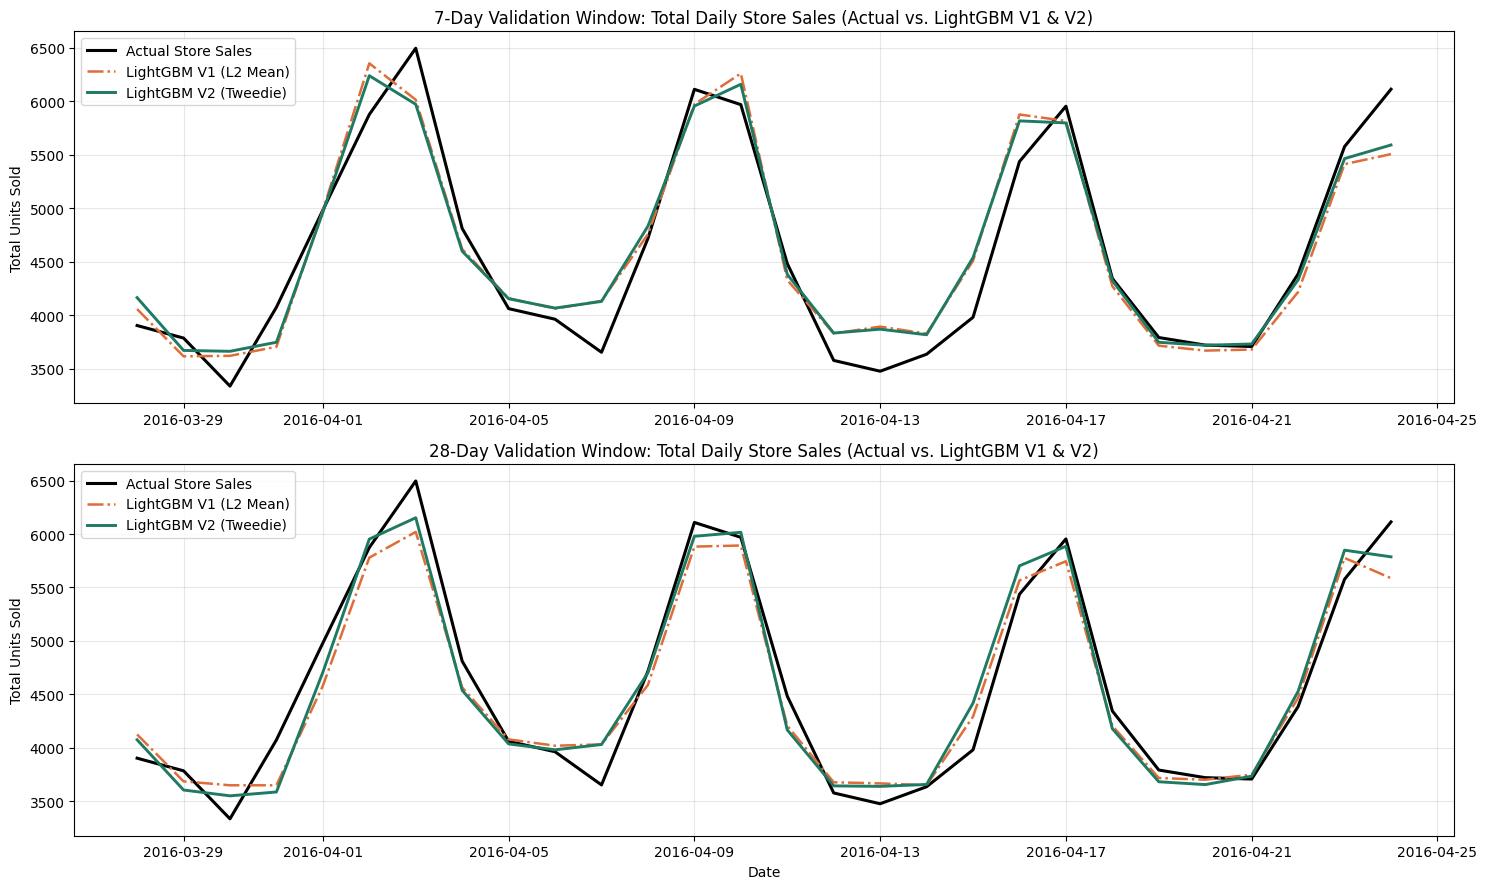

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns
vp_7 = val_7[["date", "sales"]].copy()
vp_7["pred_v1"] = np.clip(y_pred_7, 0, None)
vp_7["pred_v2"] = np.clip(y_pred_7_v2, 0, None)
daily_7 = vp_7.groupby("date")[["sales", "pred_v1", "pred_v2"]].sum().reset_index()

vp_28 = val_28[["date", "sales"]].copy()
vp_28["pred_v1"] = np.clip(y_pred_28, 0, None)
vp_28["pred_v2"] = np.clip(y_pred_28_v2, 0, None)
daily_28 = vp_28.groupby("date")[["sales", "pred_v1", "pred_v2"]].sum().reset_index()

fig, axes = plt.subplots(2, 1, figsize=(15, 9))

axes[0].plot(daily_7["date"], daily_7["sales"], label="Actual Store Sales", color="black", linewidth=2.2)
axes[0].plot(daily_7["date"], daily_7["pred_v1"], label="LightGBM V1 (L2 Mean)", color="#e06c38", linestyle="-.", linewidth=1.8)
axes[0].plot(daily_7["date"], daily_7["pred_v2"], label="LightGBM V2 (Tweedie)", color="#1f7a63", linewidth=2.1)
axes[0].set_title("7-Day Validation Window: Total Daily Store Sales (Actual vs. LightGBM V1 & V2)")
axes[0].set_ylabel("Total Units Sold")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(daily_28["date"], daily_28["sales"], label="Actual Store Sales", color="black", linewidth=2.2)
axes[1].plot(daily_28["date"], daily_28["pred_v1"], label="LightGBM V1 (L2 Mean)", color="#e06c38", linestyle="-.", linewidth=1.8)
axes[1].plot(daily_28["date"], daily_28["pred_v2"], label="LightGBM V2 (Tweedie)", color="#1f7a63", linewidth=2.1)
axes[1].set_title("28-Day Validation Window: Total Daily Store Sales (Actual vs. LightGBM V1 & V2)")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Total Units Sold")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [45]:
import os
import json
import shutil
import joblib
import numpy as np
from google.colab import drive

LOCAL_DIR = "/content/drive/MyDrive/DemandLens/Data/processed/"
TEMP_DIR  = "/content/temp_backup/"
os.makedirs(TEMP_DIR, exist_ok=True)

files_to_move = [
    "lightgbm_h7.joblib",
    "lightgbm_h28.joblib",
    "feature_lists.json",
    "h7_val_predictions.parquet"
]

# 1. Back up any already-exported files from local Colab disk before mounting
for fname in files_to_move:
    src = os.path.join(LOCAL_DIR, fname)
    if os.path.exists(src):
        shutil.copy2(src, os.path.join(TEMP_DIR, fname))

# 2. Clean local mountpoint if Drive isn't mounted yet, then mount real Google Drive
if not os.path.exists("/content/drive/.shortcut-targets-by-id") and not os.path.ismount("/content/drive"):
    !rm -rf /content/drive/*
    drive.mount("/content/drive")

REAL_OUT = "/content/drive/MyDrive/DemandLens/Data/processed/"
os.makedirs(REAL_OUT, exist_ok=True)

# 3. Copy backed-up files into real Drive (or export directly from RAM if needed)
for fname in files_to_move:
    backup_file = os.path.join(TEMP_DIR, fname)
    if os.path.exists(backup_file):
        shutil.copy2(backup_file, os.path.join(REAL_OUT, fname))

if not os.path.exists(os.path.join(REAL_OUT, "lightgbm_h7.joblib")):
    joblib.dump(model_7_v2,  os.path.join(REAL_OUT, "lightgbm_h7.joblib"))
    joblib.dump(model_28_v2, os.path.join(REAL_OUT, "lightgbm_h28.joblib"))
    with open(os.path.join(REAL_OUT, "feature_lists.json"), "w") as f:
        json.dump({
            "features_7": list(X_train_7.columns),
            "features_28": list(X_train_28.columns),
            "item_categories": list(X_train_7["item_id"].cat.categories)
        }, f, indent=2)
    val_preds_df = val_7[["item_id", "date", "sales"]].copy()
    val_preds_df["item_id"] = val_preds_df["item_id"].astype(str)
    val_preds_df["forecast"] = np.clip(y_pred_7_v2, 0, None)
    val_preds_df.to_parquet(os.path.join(REAL_OUT, "h7_val_predictions.parquet"), index=False)

print("Verified in Google Drive:", [f for f in os.listdir(REAL_OUT) if f in files_to_move])

Mounted at /content/drive
Verified in Google Drive: ['lightgbm_h7.joblib', 'lightgbm_h28.joblib', 'feature_lists.json', 'h7_val_predictions.parquet']
